# Results walkthrough

Loads the JSON artefacts written by `make train export benchmark` and walks through the inter-patient results, the quantisation trade-off and the protocol comparison. Nothing here retrains anything.

_Research/education only - not a medical device._

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
R = ROOT / 'results'
F = ROOT / 'docs' / 'figures'
load = lambda name: json.loads((R / name).read_text(encoding='utf-8'))
bench, export, card, best = load('benchmark.json'), load('export.json'), load('data_card.json'), load('best_model.json')
pd.set_option('display.precision', 4)

## 1. Data: inter-patient splits

In [2]:
pd.DataFrame({k: {'records': len(v['records']), 'beats': v['n_beats'], **v['class_counts']} for k, v in card['inter_patient'].items()}).T

,records,beats,N,S,V,F,Q
train,18,41257,37232,769,2855,399,2
val,4,9720,8592,174,933,15,6
test,22,49668,44218,1836,3219,388,7


## 2. Model selection (validation only)

In [3]:
display(Markdown(f"Selected variant: **{best['variant']}** - {best['selection']}"))
pd.Series(best['val_select_f1'], name='val F1 (N,S,V)')

Selected variant: **tiny** - highest mean validation F1 over N,S,V (same signal as early stopping) on the DS1 patient-wise hold-out

tiny     0.6575
small    0.6297
base     0.6108
Name: val F1 (N,S,V), dtype: float64

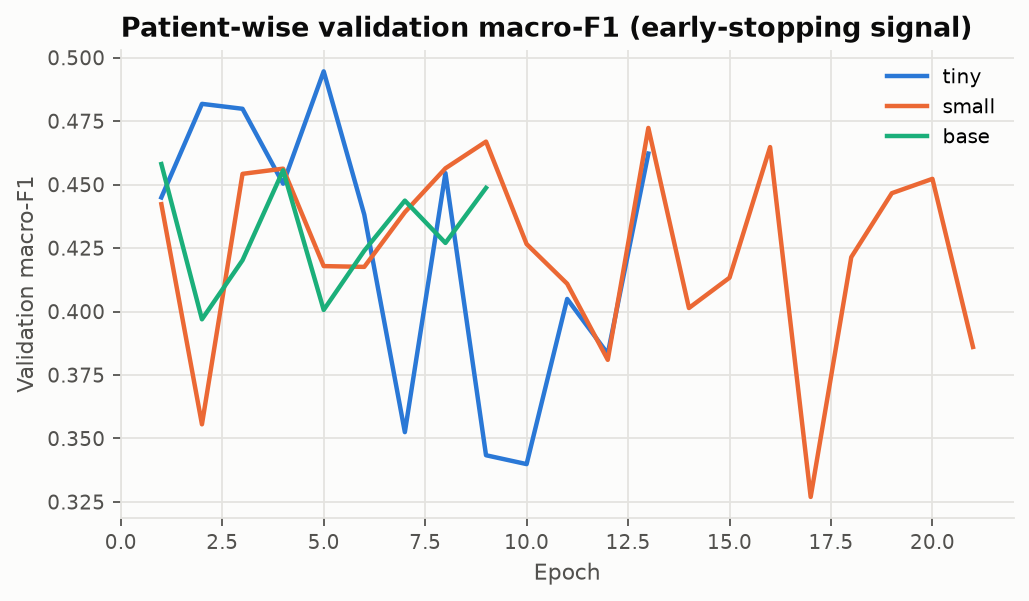

In [4]:
Image(F / 'training_curves.png')

## 3. Benchmark: every variant x runtime (DS2 test)

In [5]:
rows = []
for r in bench['rows']:
    rows.append({'variant': r['variant'], 'runtime': r['runtime_label'], 'params': r['params'], 'size_kb': r['size_kb'], 'accuracy': r['accuracy'], 'macro_f1': r['macro_f1'], **{f'F1_{c}': r['per_class_f1'][c] for c in 'NSVF'}, 'p50_ms': r['latency']['p50_ms'], 'p95_ms': r['latency']['p95_ms']})
df = pd.DataFrame(rows)
print(bench['hardware']['label'])
df

Desktop x86_64 CPU (12th Gen Intel(R) Core(TM) i5-12500H), 1 thread, batch 1 - NOT a phone


,variant,runtime,params,size_kb,accuracy,macro_f1,F1_N,F1_S,F1_V,F1_F,p50_ms,p95_ms
0,tiny,PyTorch FP32,7285,39.4404,0.8816,0.5863,0.9368,0.5168,0.8748,0.0168,0.1196,0.1663
1,tiny,LiteRT FP32,7285,45.7539,0.8816,0.5863,0.9368,0.5168,0.8748,0.0168,0.0129,0.0143
2,tiny,LiteRT int8 (full-integer),7285,21.7188,0.8906,0.5850,0.9422,0.5130,0.8725,0.0123,0.0084,0.0089
3,tiny,LiteRT int8 (dynamic-range),7285,17.0703,0.8789,0.5816,0.9351,0.5028,0.8719,0.0164,0.0095,0.0128
4,small,PyTorch FP32,28389,122.3154,0.7927,0.5566,0.8794,0.4473,0.8875,0.0122,0.1525,0.2104
5,small,LiteRT FP32,28389,128.4102,0.7927,0.5566,0.8794,0.4473,0.8875,0.0122,0.0368,0.0453
6,small,LiteRT int8 (full-integer),28389,44.7891,0.7985,0.5569,0.8830,0.4441,0.8908,0.0097,0.0153,0.0198
7,small,LiteRT int8 (dynamic-range),28389,39.0156,0.7920,0.5552,0.8788,0.4419,0.8882,0.0120,0.0195,0.0209
8,base,PyTorch FP32,112069,450.3154,0.9334,0.6322,0.9687,0.6416,0.8744,0.0443,0.2507,0.3123
9,base,LiteRT FP32,112069,455.7227,0.9334,0.6322,0.9687,0.6416,0.8744,0.0443,0.1208,0.1428


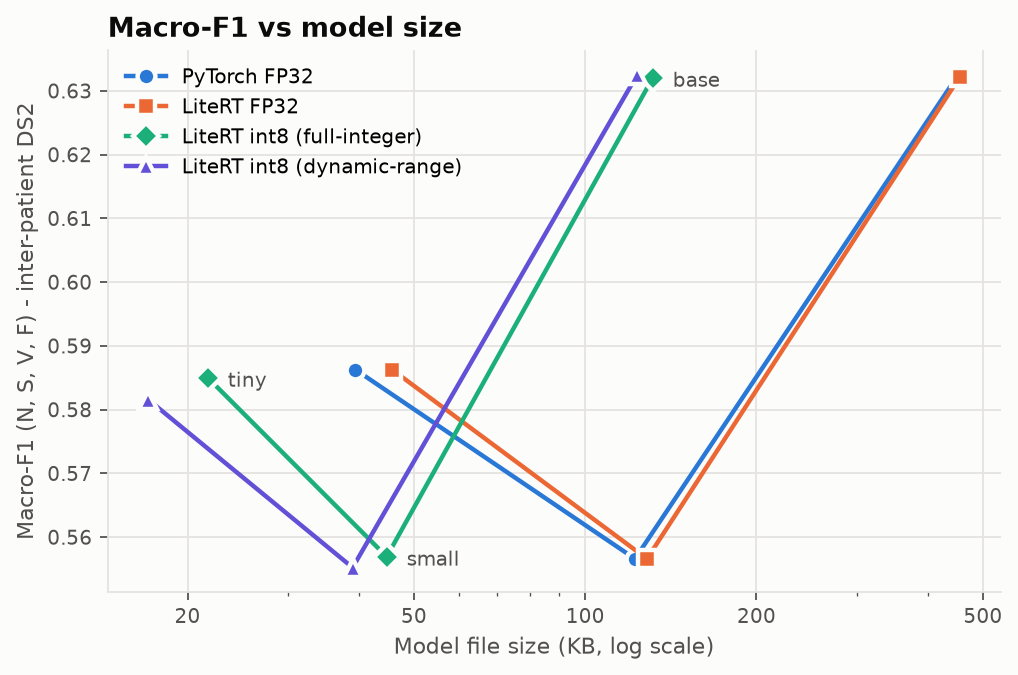

In [6]:
Image(F / 'f1_vs_size.png')

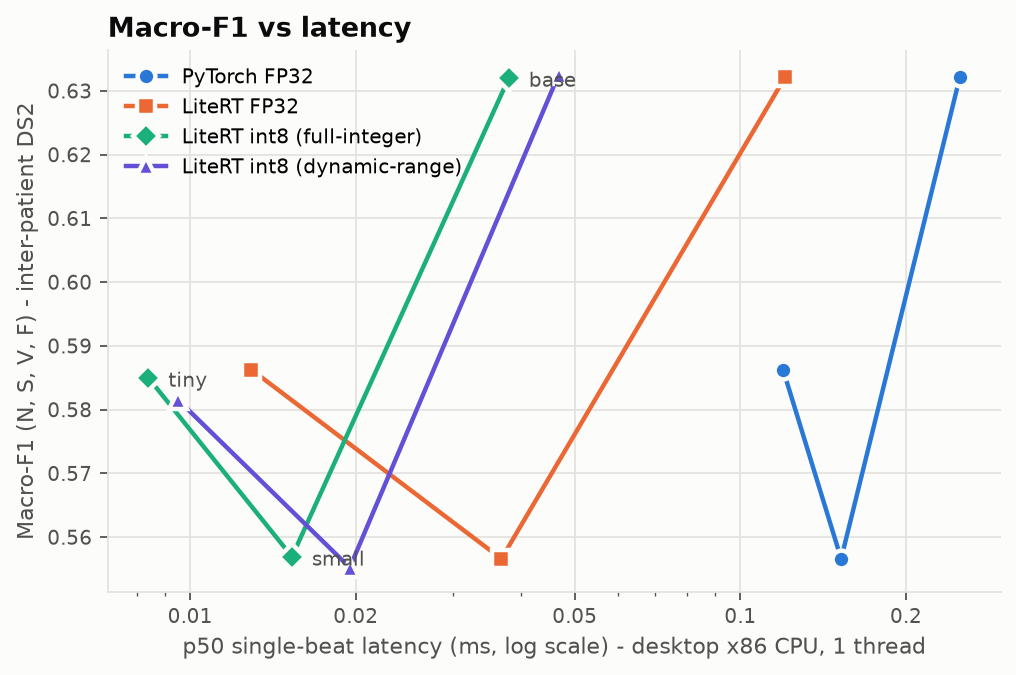

In [7]:
Image(F / 'f1_vs_latency.png')

## 4. Quantisation: FP32 vs full-integer int8

In [8]:
pd.DataFrame(bench['quantization_summary']).T

,size_reduction_x,macro_f1_delta,accuracy_delta,speedup_vs_litert_fp32_p50,speedup_vs_pytorch_fp32_p50
tiny,2.1067,-0.0013,0.0091,1.5382,14.2389
small,2.8670,0.0003,0.0058,2.4019,9.9563
base,3.4674,-0.0002,-0.0053,3.1824,6.6062


In [9]:
pd.DataFrame({v: {rt: export[v][rt]['agreement_with_pytorch'] for rt in ('litert_fp32', 'litert_int8', 'litert_int8_dynamic')} for v in export}).T.rename(columns=lambda c: c + ' agreement')

,litert_fp32 agreement,litert_int8 agreement,litert_int8_dynamic agreement
tiny,1.0,0.9832,0.9939
small,1.0,0.9854,0.9946
base,1.0,0.9912,0.9971


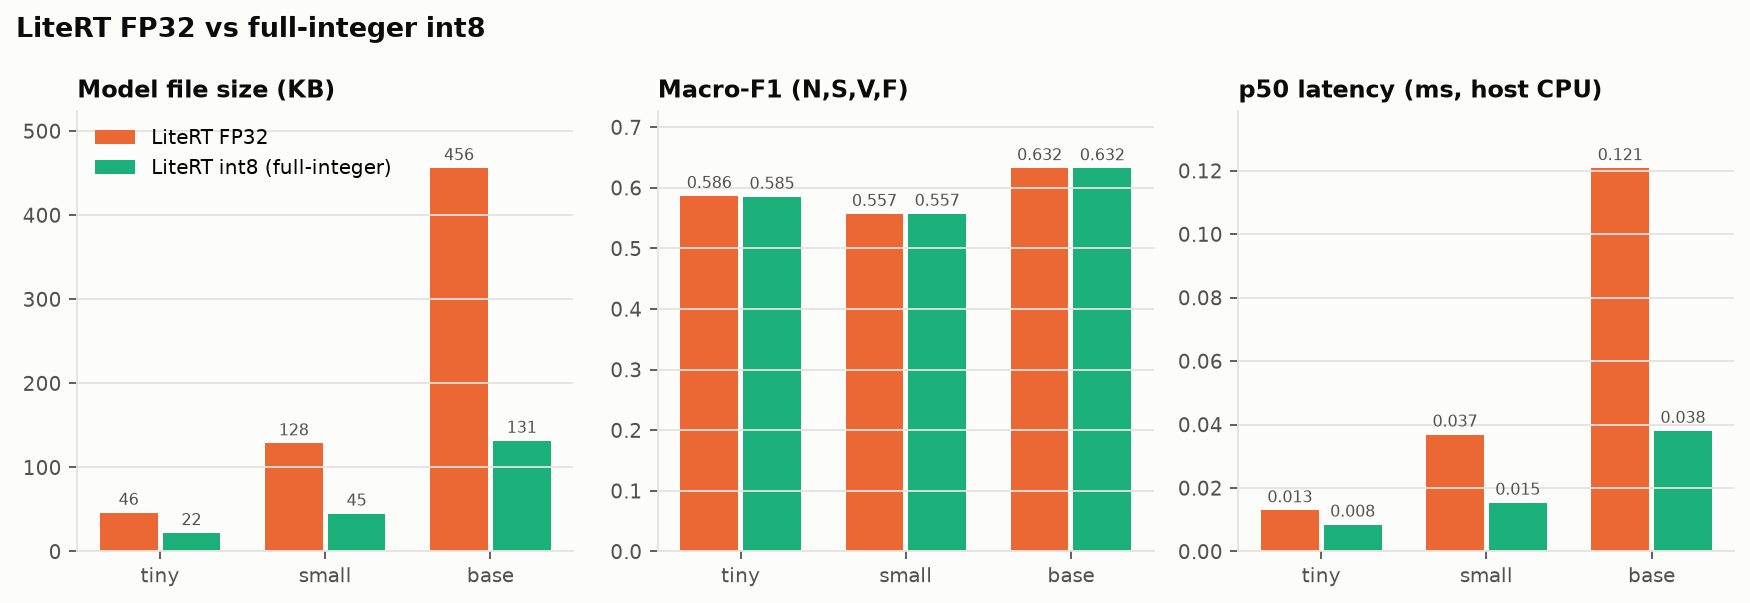

In [10]:
Image(F / 'fp32_vs_int8.png')

## 5. Best model, int8: per-class metrics and confusion matrix

In [11]:
bv = bench['best_variant']
m = export[bv]['litert_int8']['test']
pd.DataFrame(m['per_class']).T

,precision,recall,f1,support
N,0.9868,0.9014,0.9422,44218.0
S,0.3719,0.8268,0.5130,1836.0
V,0.8611,0.8841,0.8725,3219.0
F,0.0074,0.0361,0.0123,388.0
Q,0.0000,0.0000,0.0000,7.0


In [12]:
pd.DataFrame(m['confusion_matrix'], index=[f'true {c}' for c in 'NSVFQ'], columns=[f'pred {c}' for c in 'NSVFQ'])

,pred N,pred S,pred V,pred F,pred Q
true N,39858,2371,231,1758,0
true S,63,1518,219,36,0
true V,102,191,2846,80,0
true F,365,2,7,14,0
true Q,4,0,2,1,0


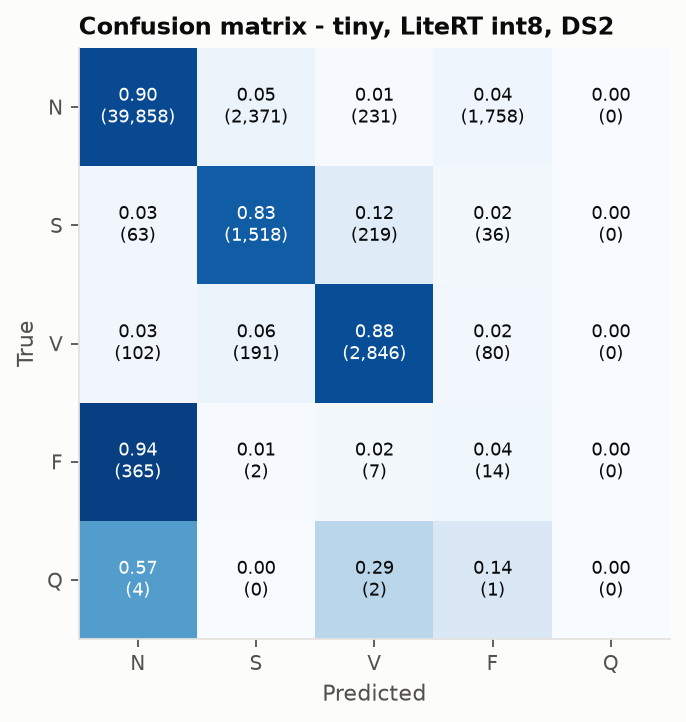

In [13]:
Image(F / 'confusion_int8_best.png')

## 6. Inter- vs intra-patient (why the protocol matters)

In [14]:
inter = load(f'eval_inter_{bv}.json')['test']
intra = load(f'eval_intra_{bv}.json')['test']
pd.DataFrame({name: {'accuracy': e['accuracy'], 'macro_f1': e['macro_f1'], **{f'F1_{c}': e['per_class'][c]['f1'] for c in 'NSVF'}} for name, e in [('inter-patient (DS1->DS2)', inter), ('intra-patient random (leaky)', intra)]}).T

,accuracy,macro_f1,F1_N,F1_S,F1_V,F1_F
inter-patient (DS1->DS2),0.8816,0.5863,0.9368,0.5168,0.8748,0.0168
intra-patient random (leaky),0.9789,0.8627,0.9891,0.8422,0.9633,0.6563


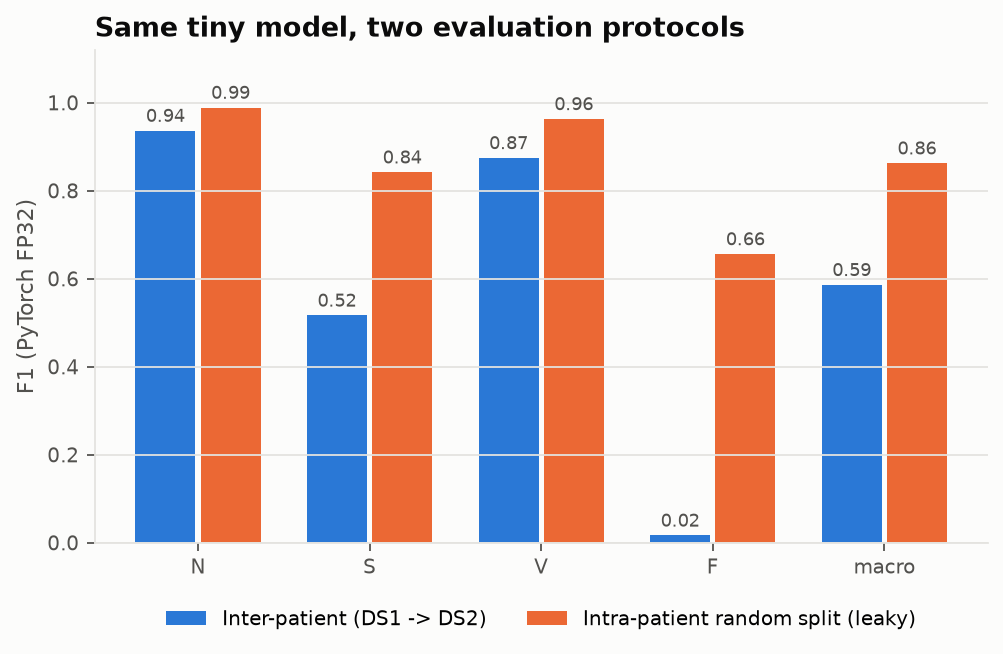

In [15]:
Image(F / 'inter_vs_intra.png')